
# Assignment 9 — Weather Reporting Agent Using LangGraph and Open-Meteo API

### Objective
Create an agent that fetches current weather information for a city using a free weather API and reports the result to the user.

### Agent Approach
This assignment uses **LangGraph** to organize the weather agent into a simple workflow:

**City Input → Find Location → Fetch Weather → Generate Report**

The **Open-Meteo API** is used because it provides weather data without requiring an API key.



### Step 1 — Install and Import Libraries

`requests` is used to communicate with the weather APIs.  
`LangGraph` is used to create the agent workflow.


In [ ]:

import requests
import matplotlib.pyplot as plt
from typing import TypedDict
from langgraph.graph import StateGraph, START, END



### Step 2 — Define Weather Codes

Open-Meteo returns a numerical weather code.  
The dictionary below converts common WMO weather codes into readable descriptions.


In [2]:

weather_codes = {
    0: "Clear sky",
    1: "Mainly clear",
    2: "Partly cloudy",
    3: "Overcast",
    45: "Fog",
    48: "Depositing rime fog",
    51: "Light drizzle",
    53: "Moderate drizzle",
    55: "Dense drizzle",
    61: "Slight rain",
    63: "Moderate rain",
    65: "Heavy rain",
    71: "Slight snow",
    73: "Moderate snow",
    75: "Heavy snow",
    80: "Slight rain showers",
    81: "Moderate rain showers",
    82: "Violent rain showers",
    95: "Thunderstorm"
}

print("Weather code mapping loaded.")


Weather code mapping loaded.



### Step 3 — Define the LangGraph State

The state stores the city, location information, weather data, and final report.


In [3]:

class WeatherState(TypedDict, total=False):
    city: str
    latitude: float
    longitude: float
    timezone: str
    temperature: float
    humidity: float
    wind_speed: float
    weather_code: int
    weather_description: str
    report: str
    error: str



### Step 4 — Find the City's Location

The Open-Meteo Geocoding API converts a city name into latitude and longitude.


In [4]:

def find_location(state):
    city = state["city"]

    url = "https://geocoding-api.open-meteo.com/v1/search"
    params = {
        "name": city,
        "count": 1,
        "language": "en",
        "format": "json"
    }

    try:
        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()
        data = response.json()

        if "results" not in data:
            state["error"] = f"Could not find the city: {city}"
            return state

        result = data["results"][0]

        state["latitude"] = result["latitude"]
        state["longitude"] = result["longitude"]
        state["timezone"] = result.get("timezone", "Unknown")

    except requests.RequestException as e:
        state["error"] = f"Location API error: {e}"

    return state



### Step 5 — Fetch Current Weather

The Forecast API is used to retrieve current temperature, humidity, wind speed, and weather condition.


In [5]:

def fetch_weather(state):
    if "error" in state:
        return state

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": state["latitude"],
        "longitude": state["longitude"],
        "current": "temperature_2m,relative_humidity_2m,weather_code,wind_speed_10m",
        "timezone": "auto"
    }

    try:
        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()
        data = response.json()

        current = data["current"]

        state["temperature"] = current["temperature_2m"]
        state["humidity"] = current["relative_humidity_2m"]
        state["wind_speed"] = current["wind_speed_10m"]
        state["weather_code"] = current["weather_code"]
        state["weather_description"] = weather_codes.get(
            current["weather_code"],
            "Unknown weather condition"
        )

    except requests.RequestException as e:
        state["error"] = f"Weather API error: {e}"

    return state



### Step 6 — Generate the Weather Report

The agent converts the API data into a simple human-readable report.


In [6]:

def generate_report(state):
    if "error" in state:
        state["report"] = "Error: " + state["error"]
        return state

    state["report"] = f'''
Weather Report for {state["city"]}
--------------------------------
Condition   : {state["weather_description"]}
Temperature : {state["temperature"]} °C
Humidity    : {state["humidity"]} %
Wind Speed  : {state["wind_speed"]} km/h
Timezone    : {state["timezone"]}
Coordinates : ({state["latitude"]:.4f}, {state["longitude"]:.4f})
'''

    return state


### Step 7 — Build the LangGraph Weather Agent
The graph connects the location, weather, and reporting nodes.

In [7]:

workflow = StateGraph(WeatherState)

workflow.add_node("find_location", find_location)
workflow.add_node("fetch_weather", fetch_weather)
workflow.add_node("generate_report", generate_report)

workflow.add_edge(START, "find_location")
workflow.add_edge("find_location", "fetch_weather")
workflow.add_edge("fetch_weather", "generate_report")
workflow.add_edge("generate_report", END)

weather_agent = workflow.compile()

print("LangGraph weather agent created successfully.")


LangGraph weather agent created successfully.



### Step 8 — Test the Agent

The default test city is Pune. You can change it to any city supported by the geocoding API.


In [8]:

city = "Pune"

result = weather_agent.invoke({
    "city": city
})

print(result["report"])



Weather Report for Pune
--------------------------------
Condition   : Light drizzle
Temperature : 28.9 °C
Humidity    : 54 %
Wind Speed  : 14.0 km/h
Timezone    : Asia/Kolkata
Coordinates : (18.5196, 73.8554)



### Step 9 — Visualize the Current Weather
A simple chart displays the main weather measurements returned by the agent.

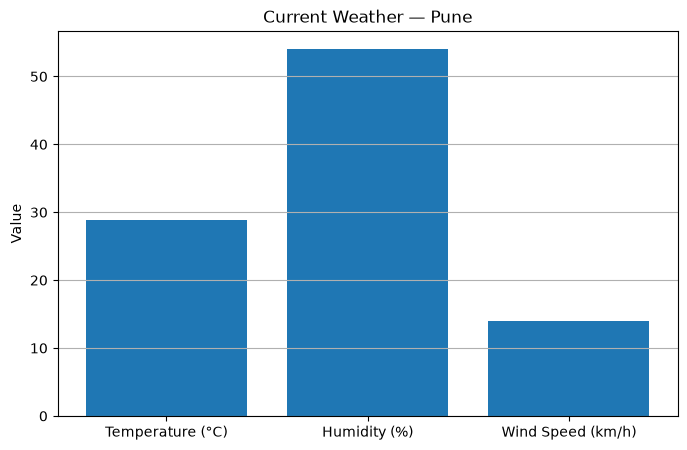

In [9]:

if "error" not in result:
    labels = ["Temperature (°C)", "Humidity (%)", "Wind Speed (km/h)"]
    values = [
        result["temperature"],
        result["humidity"],
        result["wind_speed"]
    ]

    plt.figure(figsize=(8, 5))
    plt.bar(labels, values)
    plt.ylabel("Value")
    plt.title(f"Current Weather — {result['city']}")
    plt.grid(axis="y")
    plt.show()



### Step 10 — Fetch a 12-Hour Temperature Forecast

The agent can also retrieve the next 12 hourly temperature values.


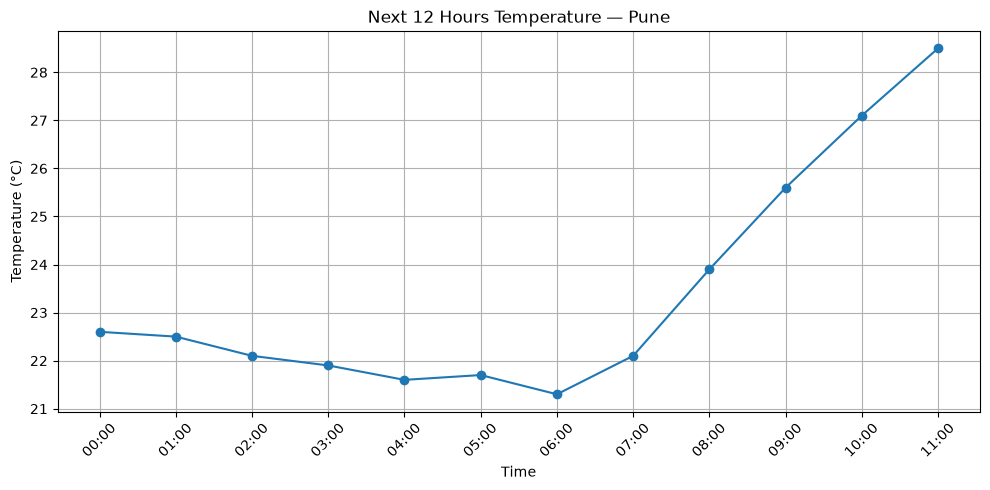

In [10]:

def get_hourly_forecast(city):
    location = weather_agent.invoke({"city": city})

    if "error" in location:
        print(location["report"])
        return None

    url = "https://api.open-meteo.com/v1/forecast"

    params = {
        "latitude": location["latitude"],
        "longitude": location["longitude"],
        "hourly": "temperature_2m",
        "forecast_days": 2,
        "timezone": "auto"
    }

    try:
        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()
        data = response.json()

        times = data["hourly"]["time"][:12]
        temperatures = data["hourly"]["temperature_2m"][:12]

        return times, temperatures

    except requests.RequestException as e:
        print("Forecast API error:", e)
        return None


forecast = get_hourly_forecast(city)

if forecast:
    times, temperatures = forecast

    plt.figure(figsize=(10, 5))
    plt.plot(range(len(temperatures)), temperatures, marker="o")
    plt.xticks(range(len(times)), [t[-5:] for t in times], rotation=45)
    plt.xlabel("Time")
    plt.ylabel("Temperature (°C)")
    plt.title(f"Next 12 Hours Temperature — {city}")
    plt.grid(True)
    plt.tight_layout()
    plt.show()



### Step 11 — Test Multiple Cities

The same LangGraph agent can be used for different cities without changing the workflow.


In [11]:

test_cities = ["Pune", "Mumbai", "Delhi"]

for city_name in test_cities:
    result = weather_agent.invoke({"city": city_name})

    print(result["report"])
    print()



Weather Report for Pune
--------------------------------
Condition   : Light drizzle
Temperature : 28.9 °C
Humidity    : 54 %
Wind Speed  : 14.0 km/h
Timezone    : Asia/Kolkata
Coordinates : (18.5196, 73.8554)



Weather Report for Mumbai
--------------------------------
Condition   : Light drizzle
Temperature : 29.0 °C
Humidity    : 70 %
Wind Speed  : 19.3 km/h
Timezone    : Asia/Kolkata
Coordinates : (19.0728, 72.8826)



Weather Report for Delhi
--------------------------------
Condition   : Overcast
Temperature : 33.8 °C
Humidity    : 54 %
Wind Speed  : 4.9 km/h
Timezone    : Asia/Kolkata
Coordinates : (28.6519, 77.2315)





### Step 12 — Interactive Weather Agent

Enter a city name to get its current weather report.

Type `exit` to stop.


In [12]:

while True:
    city_name = input("Enter city name: ").strip()

    if city_name.lower() == "exit":
        print("Weather agent stopped.")
        break

    if not city_name:
        print("Please enter a city name.")
        continue

    result = weather_agent.invoke({"city": city_name})
    print(result["report"])



Weather Report for mumbai
--------------------------------
Condition   : Light drizzle
Temperature : 29.0 °C
Humidity    : 70 %
Wind Speed  : 19.3 km/h
Timezone    : Asia/Kolkata
Coordinates : (19.0728, 72.8826)

Weather agent stopped.



### Result

The weather agent successfully uses LangGraph to process a city name, retrieve its coordinates, fetch current weather data from Open-Meteo, and generate a readable report.

### Conclusion

This assignment demonstrates an **API-based agent using LangGraph**. The graph separates the task into clear steps: finding the location, fetching weather information, and generating a report.

The use of a free API also makes the project easy to run without an API key.
